In [1]:
                ############### KNN - REGRESSION KRIGING ###############

In [11]:
########## 1. Installing and Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold
#from pykrige.ok import OrdinaryKriging
from pykrige.uk import UniversalKriging
from scipy.spatial.distance import cdist

# Setting the random seed for reproducibility
np.random.seed(42)

In [12]:
################ 2. Loading the dataset
#data = pd.read_csv('E:/VData/SData/Wells3.csv')
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [13]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [14]:
data.describe()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000
mean,15.499214,13.761732,49.371823,7.047918,49.873158,6.258383,28.451777
std,0.536874,0.508679,19.132128,0.618476,146.064968,15.023649,2.827740
min,13.930000,12.270000,15.400000,4.000000,0.000000,0.000000,10.000000
25%,15.230000,13.440000,38.000000,6.730000,9.000000,1.300000,27.000000
50%,15.480000,13.780000,48.000000,7.000000,18.000000,2.800000,29.000000
75%,15.730000,14.125000,56.000000,7.375000,35.000000,7.000000,30.000000
max,17.740000,15.830000,286.000000,10.800000,3300.000000,278.000000,35.100000


In [15]:
############# 3. Data Preparation

In [16]:
# a. Target
y = data['pH']

In [17]:
# b. Features
features = ['T', 'Depth']
X_feats = data[features]

In [18]:
# c. Coords
X_coords = data[['x_coord', 'y_coord']]

In [19]:
# d. Splitting the dataset into training and testing datasets
(X_train_c, X_test_c, X_train_f, X_test_f, y_train, y_test) = train_test_split(X_coords, X_feats, y, test_size = 0.2, random_state = 42)


In [20]:
############# 4.Fitting the KNN Regressor (Deterministic Trend Model)

In [22]:
# a. Initialization and Fit
knn = KNeighborsRegressor(n_neighbors = 7, weights = 'distance')
knn.fit(X_train_f, y_train)

,n_neighbors,7
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
# b.Predicting the KNN trend
y_train_pred_knn = knn.predict(X_train_f)
y_test_pred_knn = knn.predict(X_test_f)

In [24]:
# c. Calculating the Training and Testing Residuals
train_residuals = y_train - y_train_pred_knn
test_residuals = y_test - y_test_pred_knn

In [25]:
######## 5. Fitting the Variogram and Universal Kriging on KNN Residuals
uk = UniversalKriging(
    x = X_train_c['x_coord'].values,
    y = X_train_c['y_coord'].values,
    z = train_residuals.values,
    variogram_model = 'gaussian',
    verbose = False,
    enable_plotting = False
)

In [26]:
# Predicting the spatial residuals
krig_train_res, _ = uk.execute('points', X_train_c['x_coord'].values, X_train_c['y_coord'].values)
krig_test_res, _ = uk.execute('points', X_test_c['x_coord'].values, X_test_c['y_coord'].values)

In [27]:
############### # 6. Combining Predictions (Regression Kriging)
y_train_pred_rk = y_train_pred_knn + krig_train_res
y_test_pred_rk = y_test_pred_knn + krig_test_res

In [17]:
############## # 7. Evaluation Function (R², RMSE, MAE)

In [28]:
# a. Function Definition
def evaluate_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae


In [29]:
# b. Calculating the performance metrics
metrics = {
    "KNN Training": evaluate_metrics(y_train, y_train_pred_knn),
    "KNN Testing": evaluate_metrics(y_test, y_test_pred_knn),
    "KNN + RK Training": evaluate_metrics(y_train, y_train_pred_rk),
    "KNN + Rk Testing": evaluate_metrics(y_test, y_test_pred_rk)
}

In [30]:
# c. Printing the results
results_df = pd.DataFrame(metrics, index=['R²', 'RMSE', 'MAE']).T
print("=== MODEL PERFORMANCE COMPARISON ===")
print(results_df.round(4))

=== MODEL PERFORMANCE COMPARISON ===
                       R²    RMSE     MAE
KNN Training       0.7522  0.3159  0.1573
KNN Testing       -0.2877  0.6190  0.4468
KNN + RK Training  0.9882  0.0689  0.0181
KNN + Rk Testing  -0.3198  0.6266  0.4474


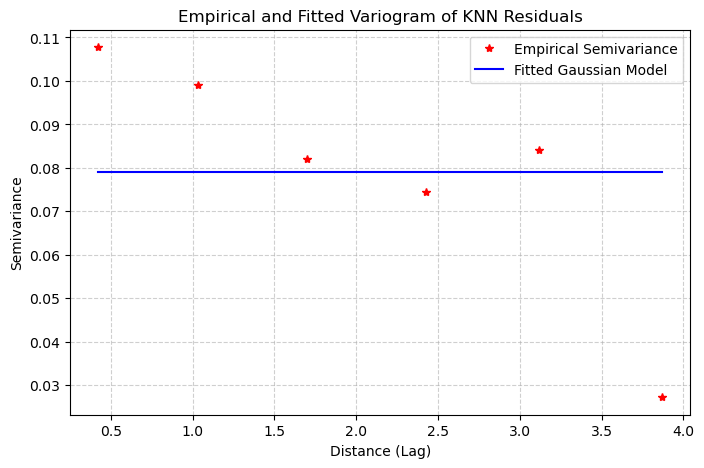

In [21]:
############## Plotting Experimental and Theoretical Variograms
plt.figure(figsize = (8, 5))
plt.plot(uk.lags, uk.semivariance, 'r*', label = 'Empirical Semivariance')
plt.plot(uk.lags, uk.variogram_function(uk.variogram_model_parameters, uk.lags), 'b-', label = 'Fitted Gaussian Model')
plt.title('Empirical and Fitted Variogram of KNN Residuals')
plt.xlabel('Distance (Lag)')
plt.ylabel('Semivariance')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.show()

In [22]:
        ########################### K-Fold Cross-Validation #########################

In [31]:
## 1. Data
coords = data[['x_coord', 'y_coord']].values
features = data[['T', 'Depth']].values
y = data['pH'].values

In [24]:
# 2. K-Fold Cross-Validation Loop
n_splits = 5
kf = KFold(n_splits = n_splits, shuffle = True, random_state = 42)

# Containers to store metrics per fold
knn_cv_metrics = {'R2': [], 'RMSE': [], 'MAE': []}
rk_cv_metrics = {'R2': [], 'RMSE': [], 'MAE': []}

for fold, (train_idx, val_idx) in enumerate(kf.split(coords)):
    # Split coordinates, features, and target
    X_train_c, X_val_c = coords[train_idx], coords[val_idx]
    X_train_f, X_val_f = features[train_idx], features[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # --- Step A: KNN Trend Model ---
    knn = KNeighborsRegressor(n_neighbors = 7, weights = 'distance')
    knn.fit(X_train_f, y_train)
    
    y_train_pred_knn = knn.predict(X_train_f)
    y_val_pred_knn = knn.predict(X_val_f)
    
    # --- Step B: Universal Kriging on Training Residuals ---
    train_residuals = y_train - y_train_pred_knn
    
    uk = UniversalKriging(
        x = X_train_c[:, 0],
        y = X_train_c[:, 1],
        z = train_residuals,
        variogram_model = 'gaussian',
        verbose = False,
        enable_plotting = False
    )
    
    # Predict residuals on validation fold using Ordinary Kriging
    # Note: PyKrige evaluate points takes individual arrays or list of points
    val_residuals_pred, _ = uk.execute('points', X_val_c[:, 0], X_val_c[:, 1])
    
    # --- Step C: Combine Predictions (Regression Kriging) ---
    y_val_pred_rk = y_val_pred_knn + val_residuals_pred
    
    # --- Step D: Store Metrics ---
    # KNN Metrics
    knn_cv_metrics['R2'].append(r2_score(y_val, y_val_pred_knn))
    knn_cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_val, y_val_pred_knn)))
    knn_cv_metrics['MAE'].append(mean_absolute_error(y_val, y_val_pred_knn))
    
    # Regression Kriging Metrics
    rk_cv_metrics['R2'].append(r2_score(y_val, y_val_pred_rk))
    rk_cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_val, y_val_pred_rk)))
    rk_cv_metrics['MAE'].append(mean_absolute_error(y_val, y_val_pred_rk))

In [25]:
# 3. Summarizing and Displaying the Results
# ---------------------------------------------------------
cv_results = pd.DataFrame({
    'KNN (R²)': np.mean(knn_cv_metrics['R2']),
    'KNN (RMSE)': np.mean(knn_cv_metrics['RMSE']),
    'KNN (MAE)': np.mean(knn_cv_metrics['MAE']),
    'KNN + RK (R²)': np.mean(rk_cv_metrics['R2']),
    'KNN + RK (RMSE)': np.mean(rk_cv_metrics['RMSE']),
    'KNN + RK (MAE)': np.mean(rk_cv_metrics['MAE'])
}, index = ['Mean CV Score']).T

In [26]:
### Printing the metric
print(f"=== {n_splits}-FOLD CROSS-VALIDATION TESTING RESULTS ===")
print(cv_results.round(4))

=== 5-FOLD CROSS-VALIDATION TESTING RESULTS ===
                 Mean CV Score
KNN (R²)               -0.2181
KNN (RMSE)              0.6734
KNN (MAE)               0.4872
KNN + RK (R²)          -0.2058
KNN + RK (RMSE)         0.6698
KNN + RK (MAE)          0.4860


In [27]:
                    ######################### Training CV Loop ########################
# 2. K-Fold Cross-Validation Loop
n_splits = 5
kf = KFold(n_splits = n_splits, shuffle = True, random_state = 42)

# Containers to store metrics per fold
knn_cv_metrics = {'R2': [], 'RMSE': [], 'MAE': []}
rk_cv_metrics = {'R2': [], 'RMSE': [], 'MAE': []}

for fold, (train_idx, val_idx) in enumerate(kf.split(coords)):
    # Split coordinates, features, and target
    X_train_c, X_val_c = coords[train_idx], coords[val_idx]
    X_train_f, X_val_f = features[train_idx], features[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # --- Step A: KNN Trend Model ---
    knn = KNeighborsRegressor(n_neighbors=7, weights='distance')
    knn.fit(X_train_f, y_train)
    
    y_train_pred_knn = knn.predict(X_train_f)
    y_val_pred_knn = knn.predict(X_val_f)
    
    # --- Step B: Ordinary Kriging on Training Residuals ---
    train_residuals = y_train - y_train_pred_knn
    
    uk = UniversalKriging(
        x = X_train_c[:, 0],
        y = X_train_c[:, 1],
        z = train_residuals,
        variogram_model = 'gaussian',
        verbose = False,
        enable_plotting = False
    )
    
    # Predict residuals on validation fold using Ordinary Kriging
    # Note: PyKrige evaluate points takes individual arrays or list of points
    train_residuals_pred, _ = uk.execute('points', X_train_c[:, 0], X_train_c[:, 1])
    
    # --- Step C: Combine Predictions (Regression Kriging) ---
    y_train_pred_rk = y_train_pred_knn + train_residuals_pred
    
    # --- Step D: Store Metrics ---
    # KNN Metrics
    knn_cv_metrics['R2'].append(r2_score(y_train, y_train_pred_knn))
    knn_cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_train, y_train_pred_knn)))
    knn_cv_metrics['MAE'].append(mean_absolute_error(y_train, y_train_pred_knn))
    
    # Regression Kriging Metrics
    rk_cv_metrics['R2'].append(r2_score(y_train, y_train_pred_rk))
    rk_cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_train, y_train_pred_rk)))
    rk_cv_metrics['MAE'].append(mean_absolute_error(y_train, y_train_pred_rk))

In [28]:
# 3. Summarizing and Displaying the Results
# ---------------------------------------------------------
cv_results = pd.DataFrame({
    'KNN (R²)': np.mean(knn_cv_metrics['R2']),
    'KNN (RMSE)': np.mean(knn_cv_metrics['RMSE']),
    'KNN (MAE)': np.mean(knn_cv_metrics['MAE']),
    'KNN + R (R²)': np.mean(rk_cv_metrics['R2']),
    'KNN + R (RMSE)': np.mean(rk_cv_metrics['RMSE']),
    'KNN + R (MAE)': np.mean(rk_cv_metrics['MAE'])
}, index=['Mean CV Score']).T

In [29]:
### Printing the metric
print(f"=== {n_splits}-FOLD CROSS-VALIDATION TRAINING RESULTS ===")
print(cv_results.round(4))

=== 5-FOLD CROSS-VALIDATION TRAINING RESULTS ===
                Mean CV Score
KNN (R²)               0.7566
KNN (RMSE)             0.3048
KNN (MAE)              0.1491
KNN + R (R²)           0.9829
KNN + R (RMSE)         0.0801
KNN + R (MAE)          0.0208
